# Análisis y visualización

## Objetivo

Analizar qué géneros cinematográficos dirigen más las mujeres y
personas no binarias en comparación con los hombres, y cómo evolucionan
su presencia y sus géneros entre 2000 y 2025.

Esta primera parte describe el conjunto completo de películas, sin
tener en cuenta todavía la dirección: cobertura por año, distribución
por géneros y evolución temporal. Sirve de referencia para interpretar
después los resultados por grupo de dirección.

## 1. Carga de los datos

Cargo las películas preparadas y defino el catálogo de géneros
obtenido de TMDB en el notebook `00_pruebas_api`.

In [9]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import find_dotenv

raiz = Path(find_dotenv(usecwd=True)).resolve().parent
carpeta_proc = raiz / "src" / "data" / "processed"
carpeta_fig = raiz / "figuras"
carpeta_fig.mkdir(exist_ok=True)

# Formato español (coma decimal, punto de miles) y colores comunes
def coma(valor, decimales=0):
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

COLOR_CATALOGO = "#4a8c8c"   # barras del catálogo (años, géneros)
COLOR_NEUTRO = "#bbbbbb"     # lo que falta o no se compara
GENERO_COLOR = {"Drama": "#8c564b", "Documental": "#e69f00", "Comedia": "#2ca02c",
                "Terror": "#7b3294", "Suspense": "#17becf", "Animación": "#bcbd22"}

df = pd.read_pickle(carpeta_proc / "peliculas_preparadas.pkl")

generos = {
    28: "Acción", 12: "Aventura", 16: "Animación", 35: "Comedia",
    80: "Crimen", 99: "Documental", 18: "Drama", 10751: "Familia",
    14: "Fantasía", 36: "Historia", 27: "Terror", 10402: "Música",
    9648: "Misterio", 10749: "Romance", 878: "Ciencia ficción",
    10770: "Película de TV", 53: "Suspense", 10752: "Bélica", 37: "Western",
}

print("Películas:", len(df))
print("Años:", df["anio_estreno"].min(), "-", df["anio_estreno"].max())

Películas: 681868
Años: 2000 - 2025


## 2. Películas por año

Cuento las películas estrenadas cada año. TMDB cataloga muchas más
películas en los años recientes, por lo que este recuento refleja en
parte el crecimiento del catálogo y no solo de la producción. Por eso,
en el resto del análisis comparo proporciones y no recuentos.

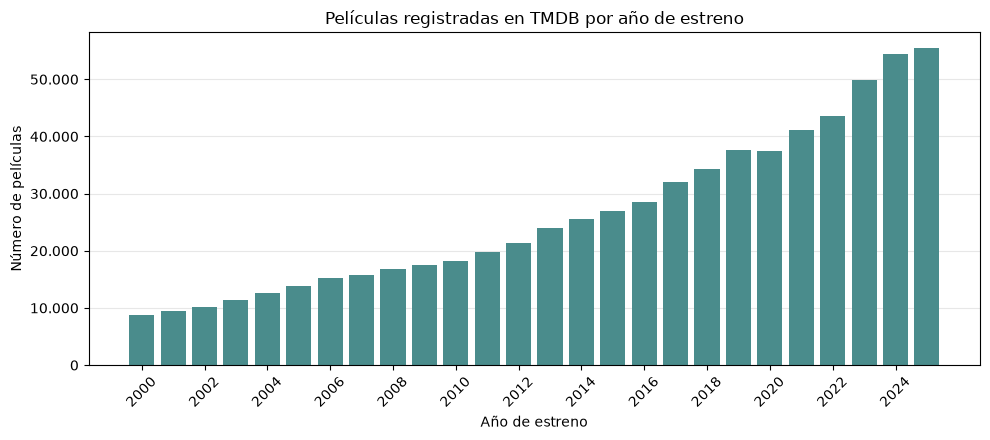

anio_estreno,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
n,8724,9417,10239,11461,12585,13779,15252,15833,16727,17524,...,28516,32050,34316,37717,37502,41056,43617,49872,54393,55443


In [10]:
por_anio = df.groupby("anio_estreno").size()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(por_anio.index, por_anio.values, color=COLOR_CATALOGO)
ax.set_title("Películas registradas en TMDB por año de estreno")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("Número de películas")
ax.set_xticks(por_anio.index[::2])
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter(lambda x, _: coma(x))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig(carpeta_fig / "01_peliculas_por_anio.png", dpi=200)
plt.show()

display(por_anio.to_frame("n").T)

El número de películas registradas crece de forma sostenida: pasa de
unas 8.700 en 2000 a más de 55.000 en 2025. Solo hay un pequeño
retroceso en 2020. Este aumento refleja en gran parte que TMDB
cataloga más películas en los años recientes, no solo que se produzca
más cine. Por eso, en el resto del análisis comparo proporciones y no
recuentos.

## 3. Expansión de los géneros

Una película puede tener varios géneros. Creo una tabla con una fila
por película y género. Las películas con la lista `genre_ids` vacía se
etiquetan como «Sin género». También compruebo que ningún
identificador de género queda fuera del catálogo.

In [11]:
df_gen = df[["id", "anio_estreno", "genre_ids"]].copy()
df_gen["genre_ids"] = df_gen["genre_ids"].apply(lambda x: x if len(x) > 0 else [None])
df_gen = df_gen.explode("genre_ids")

fuera = df_gen.loc[
    df_gen["genre_ids"].notna() & ~df_gen["genre_ids"].isin(generos), "genre_ids"
].unique()
print("IDs de género fuera del catálogo:", fuera)

df_gen["genero"] = df_gen["genre_ids"].map(generos).fillna("Sin género")
print("Filas película-género:", len(df_gen))
print("Películas únicas:", df_gen["id"].nunique())

IDs de género fuera del catálogo: []
Filas película-género: 962121
Películas únicas: 681868


Todos los identificadores de género de las películas están en el
catálogo de TMDB. La expansión genera 962.121 filas película-género
y conserva las 681.868 películas, incluidas las que no tienen género
identificado.

## 4. Géneros más frecuentes

Calculo el porcentaje de películas que pertenece a cada género. Como
una película puede tener varios géneros, los porcentajes no suman 100 %.

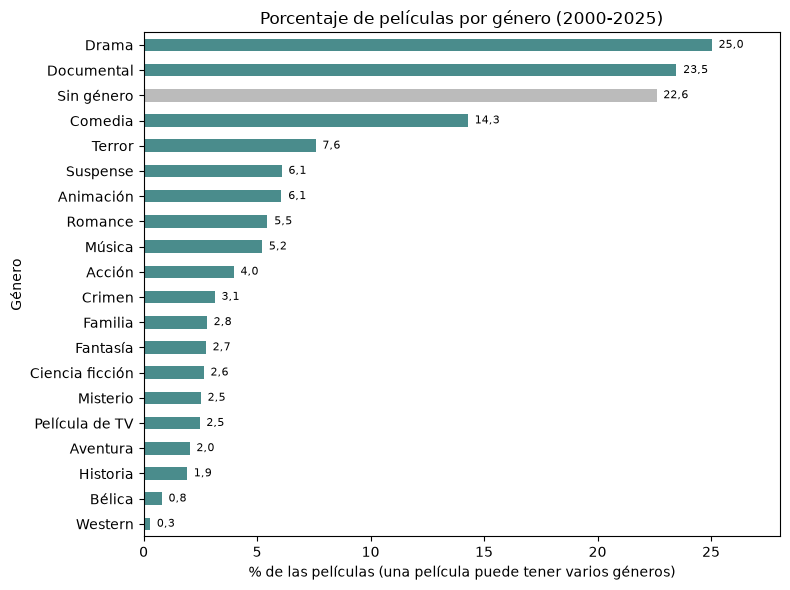

In [12]:
ranking = (df_gen.groupby("genero")["id"].nunique() / len(df) * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
colores = [COLOR_NEUTRO if gen == "Sin género" else COLOR_CATALOGO for gen in ranking.index]
ranking.plot.barh(ax=ax, color=colores)
ax.set_ylabel("Género")
ax.set_title("Porcentaje de películas por género (2000-2025)")
ax.set_xlabel("% de las películas (una película puede tener varios géneros)")
ax.set_xlim(0, ranking.max() * 1.12)
ax.xaxis.set_major_formatter(lambda x, _: coma(x))
for i, v in enumerate(ranking):
    ax.text(v + 0.3, i, coma(v, 1), va="center", fontsize=8)
plt.tight_layout()
fig.savefig(carpeta_fig / "02_generos_frecuentes.png", dpi=200)
plt.show()

## 5. Evolución de los géneros principales

Calculo, para cada año, el porcentaje de películas de ese año que
pertenece a cada género. Represento los seis géneros más frecuentes
con género identificado. Uso proporciones porque el catálogo de TMDB
crece con los años.

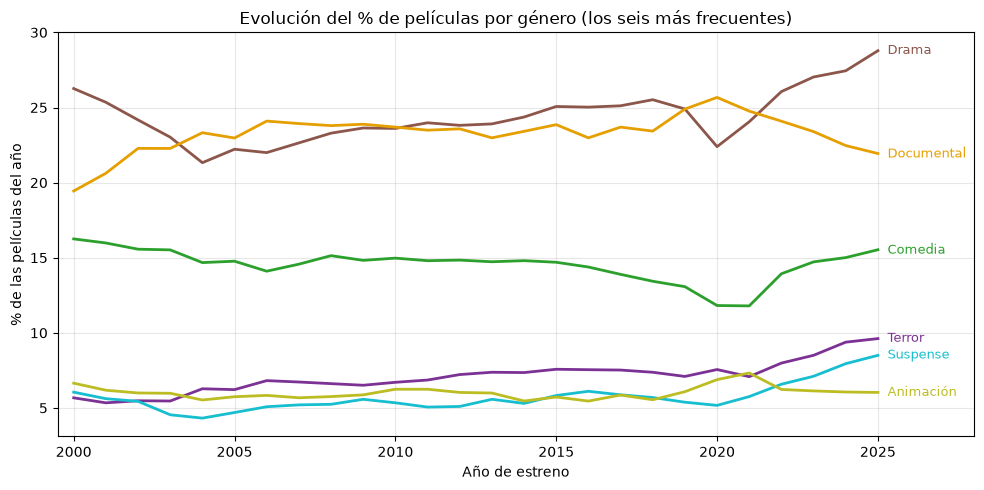

In [13]:
total_anio = df.groupby("anio_estreno").size()
tabla = df_gen.groupby(["anio_estreno", "genero"])["id"].nunique().unstack(fill_value=0)
prop = tabla.div(total_anio, axis=0) * 100

top6 = ranking.drop("Sin género").sort_values(ascending=False).head(6).index

fig, ax = plt.subplots(figsize=(10, 5))
ultimo_anio = prop.index.max()
for gen in top6:
    color = GENERO_COLOR.get(gen, "#666666")
    ax.plot(prop.index, prop[gen], color=color, linewidth=2)
    # Nombre del género al final de su línea
    ax.text(ultimo_anio + 0.3, prop.loc[ultimo_anio, gen], gen,
            color=color, va="center", fontsize=9)
ax.set_xlim(prop.index.min() - 0.5, ultimo_anio + 3)
ax.set_title("Evolución del % de películas por género (los seis más frecuentes)")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("% de las películas del año")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(carpeta_fig / "03_evolucion_generos.png", dpi=200)
plt.show()

### Evolución de las películas sin género identificado

Compruebo si la falta de género cambia a lo largo del tiempo, porque
afectaría a la interpretación de la evolución por géneros.

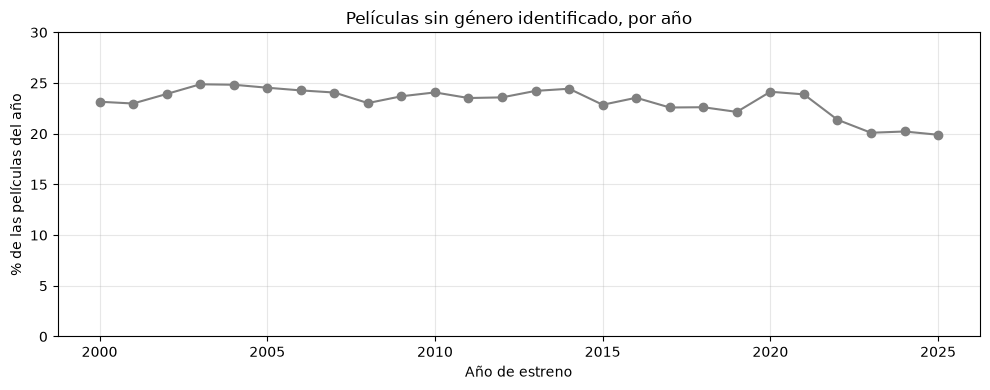

In [14]:
sin_gen = prop["Sin género"]

fig, ax = plt.subplots(figsize=(10, 4))
sin_gen.plot(ax=ax, color="gray", marker="o")
ax.set_title("Películas sin género identificado, por año")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("% de las películas del año")
ax.set_ylim(0, 30)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(carpeta_fig / "04_sin_genero_por_anio.png", dpi=200)
plt.show()

## 6. Comprobación de las fechas del 1 de enero

En la descarga, enero tiene muchas más páginas que el resto de meses.
Compruebo cuántas películas tienen como fecha el 1 de enero de su año,
lo que sugiere una fecha de relleno cuando se desconoce el día real.
Por este motivo analizo la evolución solo por año, no por mes.

In [15]:
df["es_1_enero"] = (df["release_date"].dt.month == 1) & (df["release_date"].dt.day == 1)
res = df.groupby("anio_estreno")["es_1_enero"].agg(n="sum", pct="mean")
res["pct"] = (res["pct"] * 100).round(1)
display(res.T)

anio_estreno,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
n,2387.0,2392.0,2423.0,2775.0,3043.0,3192.0,3476.0,3229.0,3301.0,3362.0,...,2993.0,3113.0,2894.0,2564.0,2271.0,2543.0,1527.0,2051.0,1796.0,1300.0
pct,27.4,25.4,23.7,24.2,24.2,23.2,22.8,20.4,19.7,19.2,...,10.5,9.7,8.4,6.8,6.1,6.2,3.5,4.1,3.3,2.3


In [8]:
# Cifras para el texto de interpretación
print(ranking.sort_values(ascending=False).round(1).head(5))
print()
print(prop.loc[[2000, 2025], top6].round(1).T)
print()
print("Sin género:", prop["Sin género"].loc[[2000, 2005, 2010, 2015, 2020, 2025]].round(1).to_dict())

genero
Drama         25.0
Documental    23.5
Sin género    22.6
Comedia       14.3
Terror         7.6
Name: id, dtype: float64

anio_estreno  2000  2025
genero                  
Drama         26.3  28.8
Documental    19.4  21.9
Comedia       16.3  15.5
Terror         5.7   9.6
Suspense       6.1   8.5
Animación      6.6   6.0

Sin género: {2000: 23.2, 2005: 24.5, 2010: 24.1, 2015: 22.9, 2020: 24.1, 2025: 19.9}


In [16]:
# Cifras para el texto de interpretación
print(ranking.sort_values(ascending=False).round(1).head(5))
print()
print(prop.loc[[2000, 2025], top6].round(1).T)
print()
print("Sin género:", prop["Sin género"].loc[[2000, 2005, 2010, 2015, 2020, 2025]].round(1).to_dict())

genero
Drama         25.0
Documental    23.5
Sin género    22.6
Comedia       14.3
Terror         7.6
Name: id, dtype: float64

anio_estreno  2000  2025
genero                  
Drama         26.3  28.8
Documental    19.4  21.9
Comedia       16.3  15.5
Terror         5.7   9.6
Suspense       6.1   8.5
Animación      6.6   6.0

Sin género: {2000: 23.2, 2005: 24.5, 2010: 24.1, 2015: 22.9, 2020: 24.1, 2025: 19.9}


## Resultados de esta primera parte

**Géneros más frecuentes.** Drama es el género más frecuente, con un
25,0 % de las películas, seguido de Documental (23,5 %) y Comedia
(14,3 %). Documental queda por delante de Comedia: es una
característica del catálogo de TMDB, y con estos datos no se puede
saber si refleja la producción real. Como una película puede tener
varios géneros, los porcentajes no suman 100 %.

**Películas sin género.** El 22,6 % de las películas no tiene género
informado. A lo largo de los años se mueve en torno al 22-25 % y baja
hasta el 19,9 % en 2025, desde el 23,2 % de 2000. Por tanto, la falta
de género no cambia mucho el panorama, pero afecta a todos los años.

**Cambios entre 2000 y 2025.** Los géneros que más ganan peso son
Terror (del 5,7 % al 9,6 %), Drama (del 26,3 % al 28,8 %), Documental
(del 19,4 % al 21,9 %) y Suspense (del 6,1 % al 8,5 %). Comedia y
Animación pierden algo (del 16,3 % al 15,5 % y del 6,6 % al 6,0 %).
Esta comparación usa solo dos años, y entre ellos hay oscilaciones,
como el descenso de Drama y Comedia en 2020, por lo que indica la
tendencia general y no cifras exactas.

Estos resultados describen todas las películas, sin separar por
dirección. En el notebook `03b_comparacion_direccion` se comparan los
géneros según el grupo de dirección.